# LUMA - Lokalny Urok Mistrzostwa Artystycznego 
LUMA to lokalny jarmark, któy rośnie z tygodnia na tydzień: coraz więcej wystawców,
więcej gości (miejscowych i turystów), okazjonalne promocje i sezonowość

 # import bibliotek

In [21]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

# Wygenerowanie syntetycznych dancyh na potrzebyt analizy 

# Ustawienie ziarna RNG

In [22]:
RNG_SEED= 20261020
rng = np.random.default_rng(RNG_SEED)
print("ustawiono ziarno RNG:", RNG_SEED)

ustawiono ziarno RNG: 20261020


### zdefiniowanie "stałych" 

In [23]:
LUMA_FULL= "Lokalny Urok Mistrzostwa Artystycznego"
CATEGORIES = ["Ceramika", "Tekstylia","Biżuteria","Rękodzieło", "Przetwory","Dekoracje",
"Stolarka", "Masarstwo","Alkohole"]

### Przygotowanie bazowych danych syntetycznych

"Katalog" kategorii i ich bazowe parametry generatywne (syntetyczne)

In [24]:
catalog = pd.DataFrame({
    "category": CATEGORIES,
    "demand_loc_base":[120,180,130,80,160,150,70,90,110], # średni lokalny popyt (szt./tydz)
    "demand_tur_base":[60,40,80,30,90,30,50,40,80],# sredni popyt turystyczny
    "price_pln_base":[8,120,150,230,40,35,250,215,135],#srednia cena jednostkowa 
}
)

Wyliczony "typowy" przychód tygodniowy : (lokalni + turyści ) * cena

In [25]:
catalog["revenue_avg_pln"] = (catalog["demand_loc_base"] + catalog["demand_tur_base"])*catalog["price_pln_base"]

In [26]:
catalog

,category,demand_loc_base,demand_tur_base,price_pln_base,revenue_avg_pln
0,Ceramika,120,60,8,1440
1,Tekstylia,180,40,120,26400
2,Biżuteria,130,80,150,31500
3,Rękodzieło,80,30,230,25300
4,Przetwory,160,90,40,10000
5,Dekoracje,150,30,35,6300
6,Stolarka,70,50,250,30000
7,Masarstwo,90,40,215,27950
8,Alkohole,110,80,135,25650


### przygotowanie funkcji pomocniczych do generowania dancyh tygodniowych

generowanie popytu lokalnego i turystycznego na podstawie danych bazowych z losowym szumem(multyplikatywnym) i opcjonalnymi boostami (%)

In [28]:
def detarminate_demand(catalog,rng, variance = 0.15,boost_loc = 0.0,boost_tur=0.0):
    df = catalog[["category","demand_loc_base","demand_tur_base"]].copy()
    eps_loc = np.clip(rng.normal(loc=1.0,scale=variance,size=len(df)),0.5,1.8)
    eps_tur = np.clip(rng.normal(loc=1.0,scale=variance,size=len(df)),0.5,1.8)
    df["demand_loc"]= (df["demand_loc_base"]* (1+ boost_loc))* eps_loc
    df["demand_tur"]= (df["demand_tur_base"]* (1+ boost_tur))* eps_tur
    df["demand_loc"] = np.maximum(df["demand_loc"].round().astype(int),0)
    df["demand_tur"] = np.maximum(df["demand_tur"].round().astype(int),0)
    return df[["category","demand_loc","demand_tur"]]

In [29]:
def count_revenue(catalog,demand_of):
    df = demand_of.merge(catalog[["category","price_pln_base"]],on = "category",how="left")
    df["revenue_loc"]= df["demand_loc"]*df["price_pln_base"]
    df["revenue_tur"]= df["demand_tur"]*df["price_pln_base"]
    df["revenue_pln"]= df["revenue_loc"]*df["revenue_tur"]
    return df[["category", "demand_loc","demand_tur","revenue_pln"]]

In [30]:
def generate_weekly_data(catalog,rng,variance=0.15,boost_loc = 0.0, boost_tur=0.0):
    demand_df=detarminate_demand(catalog,rng,variance=variance, boost_loc=boost_loc, boost_tur=boost_tur)
    revenue_df = count_revenue(catalog,demand_df)
    return revenue_df

In [33]:
t1= generate_weekly_data(catalog, rng)
t1 = t1.merge(catalog[["category","price_pln_base"]], on="category",how="left")
print("tydzien 1 -przychody per kategoria (pln)")
display(t1)
print("łaczny przychod w tygdoniu 1(pln)", t1["revenue_pln"].sum())

tydzien 1 -przychody per kategoria (pln)


,category,demand_loc,demand_tur,revenue_pln,price_pln_base
0,Ceramika,138,55,485760,8
1,Tekstylia,158,31,70531200,120
2,Biżuteria,131,71,209272500,150
3,Rękodzieło,102,33,178061400,230
4,Przetwory,176,86,24217600,40
5,Dekoracje,169,26,5382650,35
6,Stolarka,73,45,205312500,250
7,Masarstwo,84,53,205793700,215
8,Alkohole,119,60,130126500,135


łaczny przychod w tygdoniu 1(pln) 1029183810


### Analiza i wizualizacja dancyh

podstawowe wykresy

<Axes: >

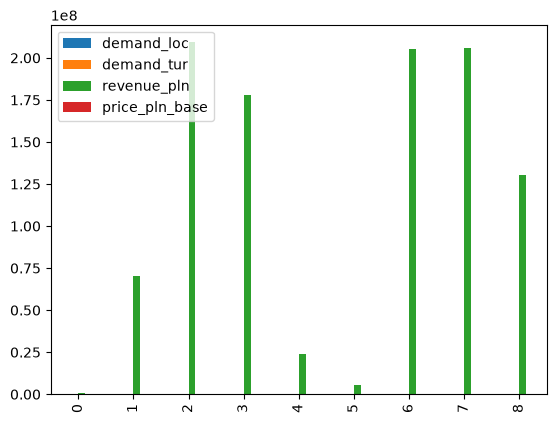

In [34]:
t1.plot.bar()

<BarContainer object of 9 artists>

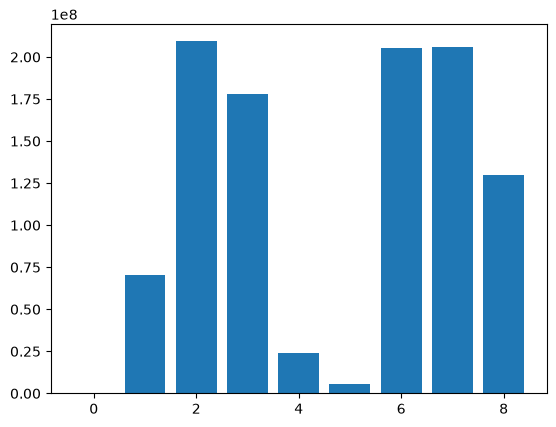

In [35]:
heights = t1["revenue_pln"]
plt.bar(range(len(heights)), heights)

jawne tworzenie i wyświetlanie wykresu 

In [36]:
hoights = t1["revenue_pln"]
categories = t1["category"]

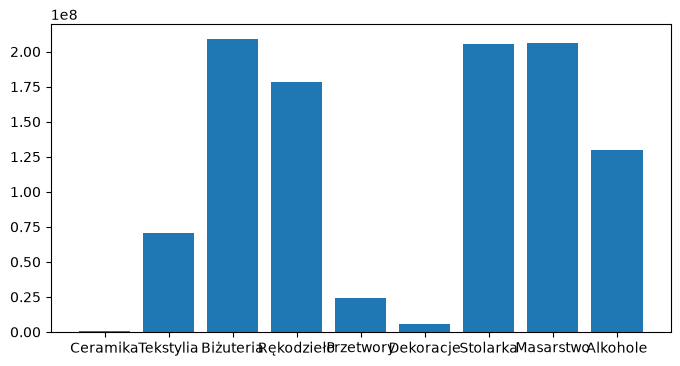

In [37]:
plt.figure(figsize=(8,4))
plt.bar(categories,hoights)
plt.show()

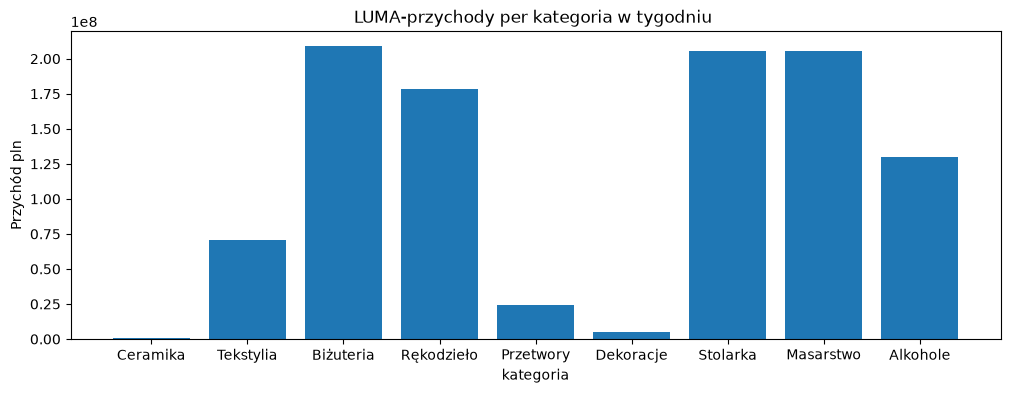

In [38]:
plt.figure(figsize=(12,4))
plt.bar(categories,hoights)
plt.title("LUMA-przychody per kategoria w tygodniu ")
plt.xlabel("kategoria")
plt.ylabel("Przychód pln")
plt.show()

etykiety wartości i formatowania liczb